## Long straight passage dynamics (Flag 18)

### Dataset Overview
Eighteen constructed passages by one cargo vessel, including normal status transitions and three temporary-anchor exceptions.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Analyze the vessel movement patterns along a long and relatively straight passage.

Role: Maritime traffic analyst


Category: long straight passage dynamics

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How stable is the vessel during long passage transits?

#### Analysis action

Compare complete passage geometry with heading and COG stability.

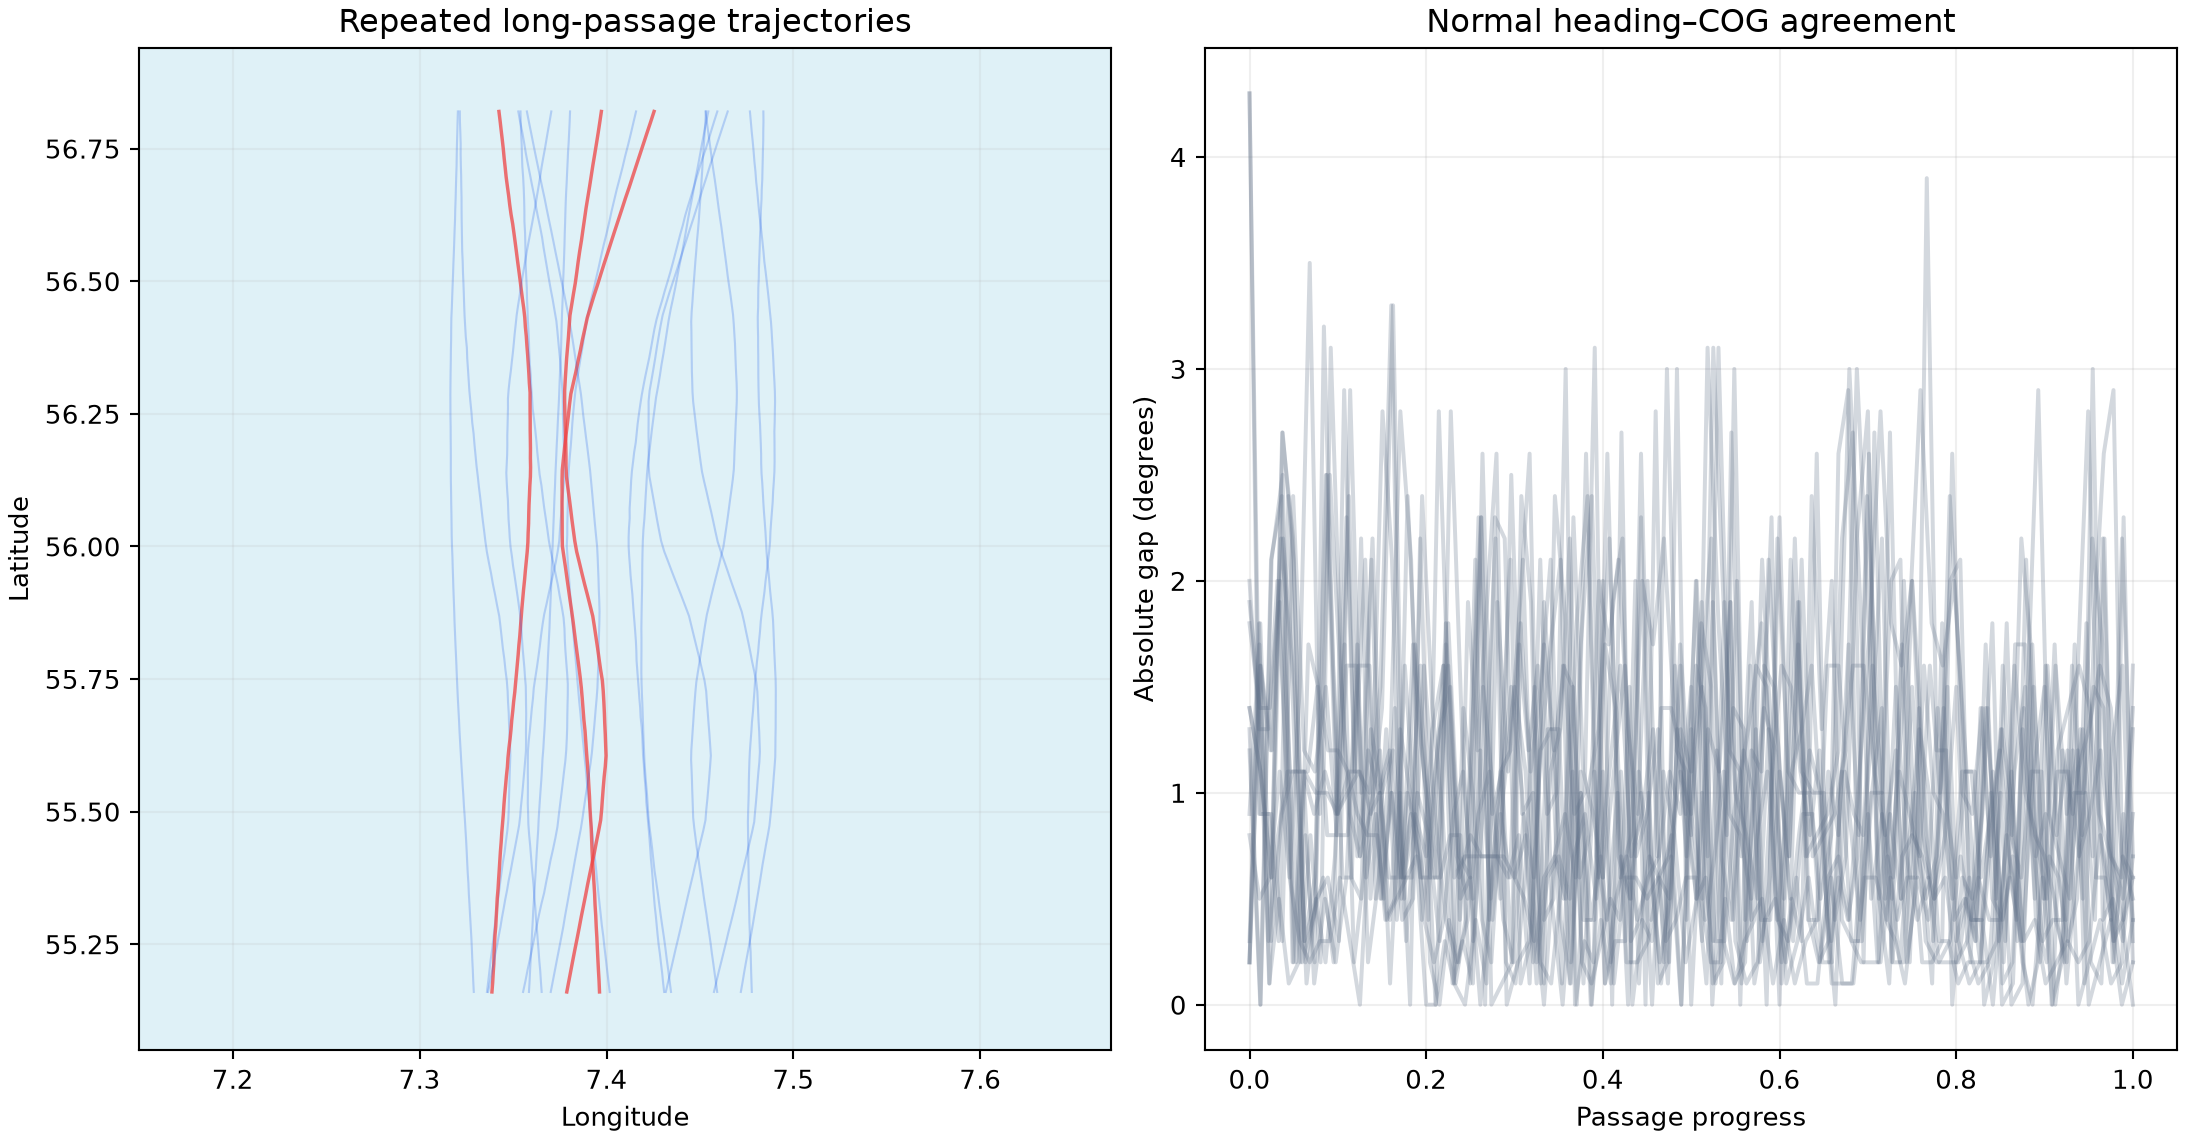

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); print(df.groupby('trajectory_id')[['cog','heading']].std())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/passage_overview.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "straight_passage_stability",
  "insight": "The vessel maintains stable heading and COG and nearly straight trajectories over long portions of the passage, with only limited directional changes during the main transit phase.",
  "insight_value": {
    "median_max_cross_track_deviation_km": 1.19
  },
  "plot": {
    "plot_type": "trajectory_map_and_direction_profile",
    "title": "Long Straight Passage Stability",
    "file": "visualizations/passage_overview.png",
    "description": "Compare complete passage geometry with heading and COG stability."
  },
  "question": "How stable is the vessel during long passage transits?",
  "actionable_insight": "Compare complete passage geometry with heading and COG stability.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); print(df.groupby('trajectory_id')[['cog','heading']].std())",
  "insight_type": "overall_pattern",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "heading",
    "course_over_ground",
    "vessel_id",
    "trajectory_timestamp",
    "navigation_status"
  ]
}

### **Question 2**: How do navigation status and speed normally change during transit?

#### Analysis action

Align trips by progress and compare navigation status with speed development.

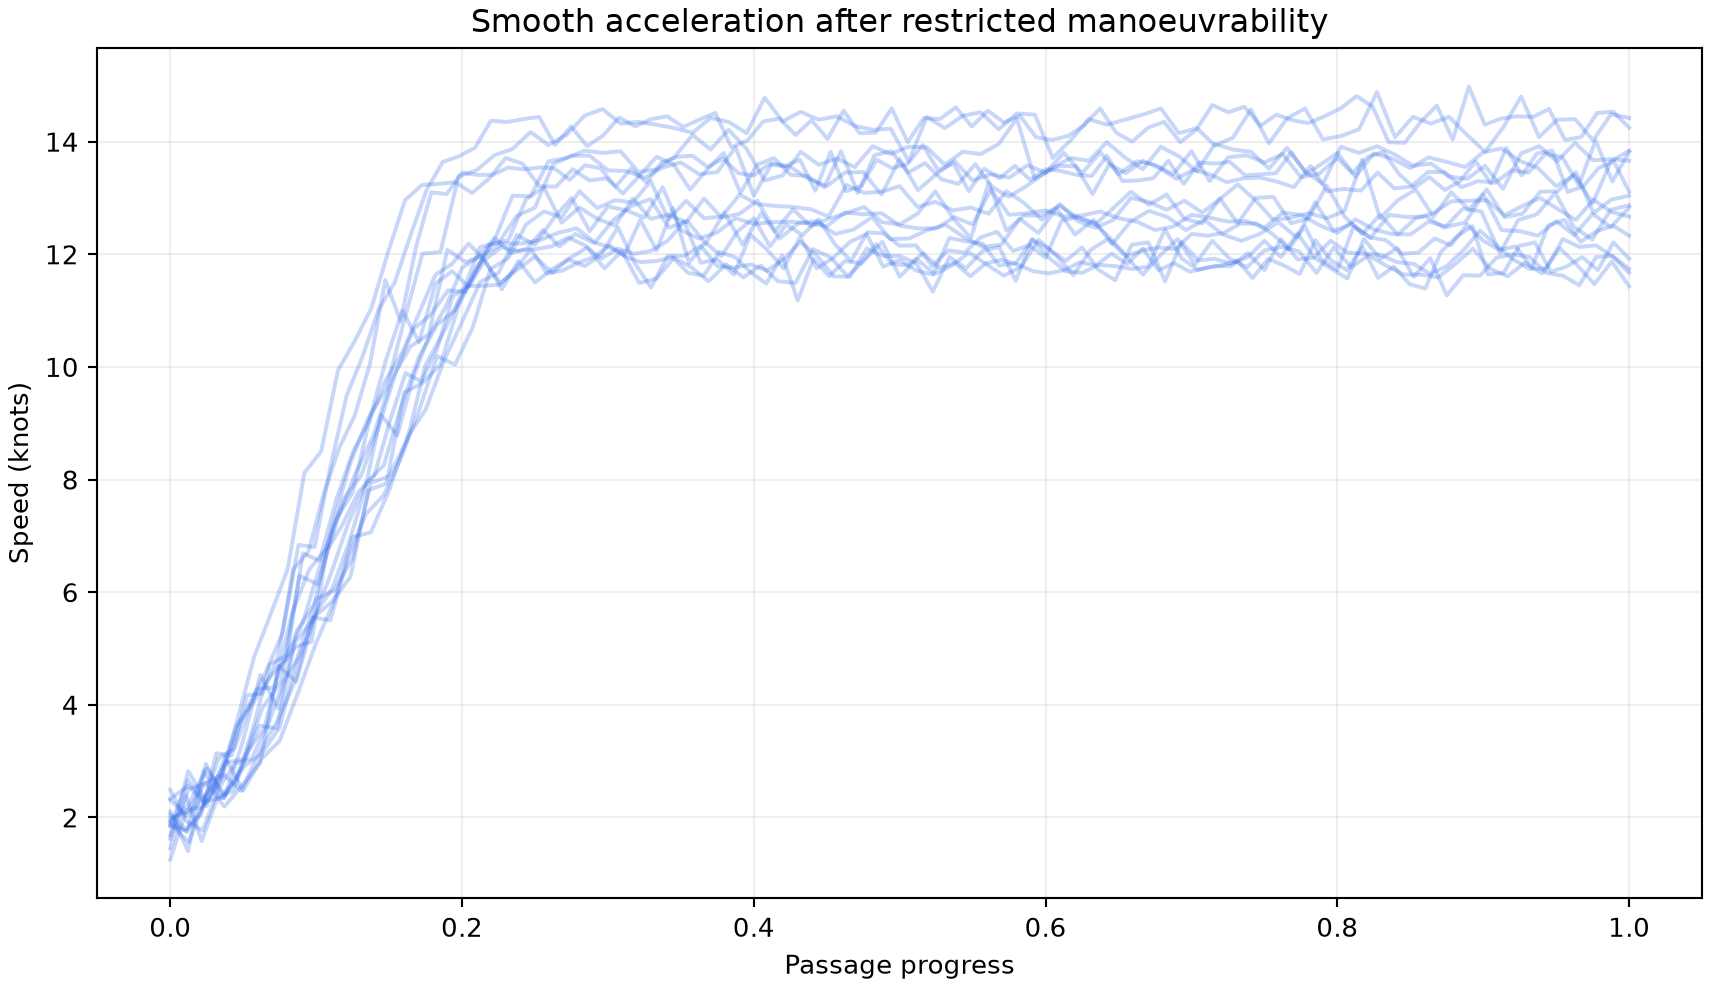

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); print(df.groupby('nav_status').sog_knots.describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/status_speed_transition.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "status_speed_transition",
  "insight": "Each passage generally includes a status transition phase, during which the vessel changes from restricted manoeuvrability to under way using engine, accompanied by a smooth increase in speed.",
  "insight_value": {
    "median_speed_increase_knots": 8.5
  },
  "plot": {
    "plot_type": "aligned_status_speed_profile",
    "title": "Status Transition and Speed Increase",
    "file": "visualizations/status_speed_transition.png",
    "description": "Align trips by progress and compare navigation status with speed development."
  },
  "question": "How do navigation status and speed normally change during transit?",
  "actionable_insight": "Align trips by progress and compare navigation status with speed development.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); print(df.groupby('nav_status').sog_knots.describe())",
  "insight_type": "overall_pattern",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "navigation_status",
    "point_speed",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### **Question 3**: Which passages show heading changes without a matching COG response?

#### Analysis action

Contrast the few anchor episodes with normal heading–COG agreement.

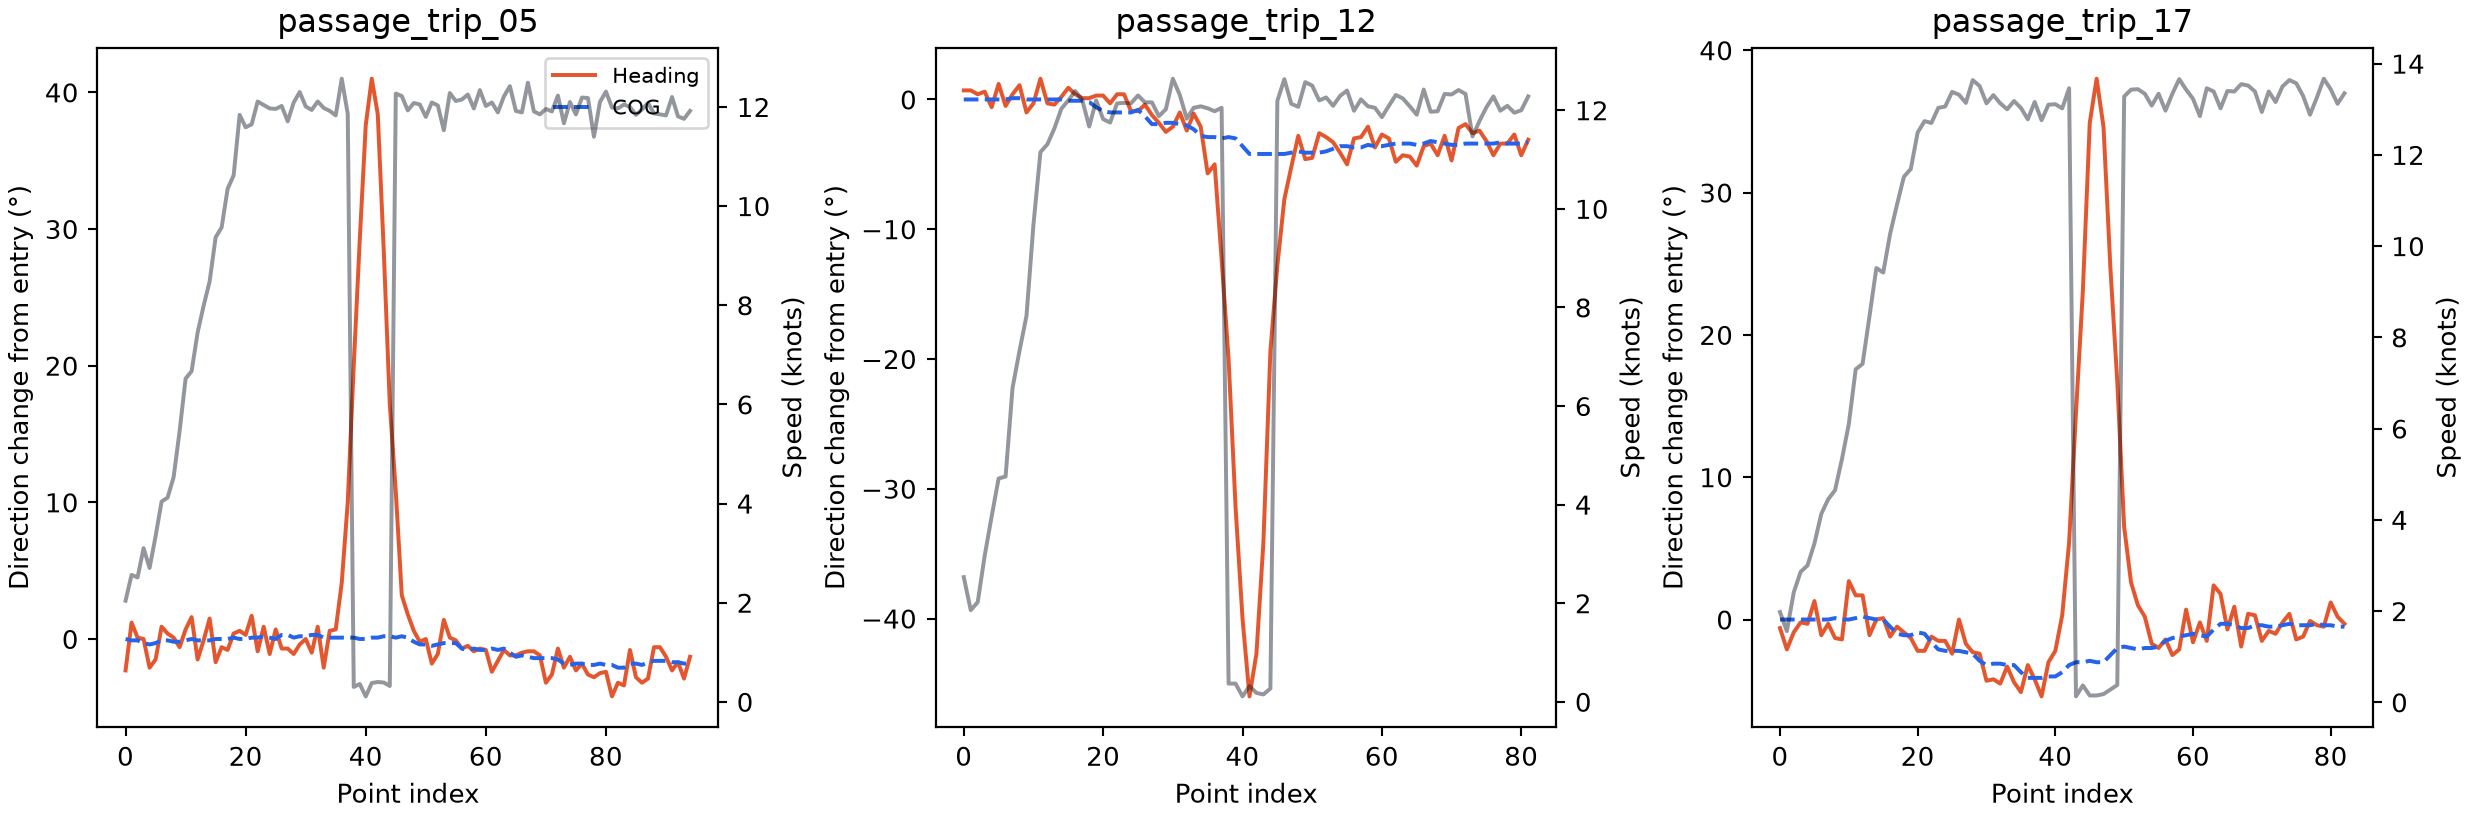

In [ ]:
import pandas as pd, numpy as np
df=pd.read_csv(dataset_path); df['gap']=abs((df.heading-df.cog+180)%360-180); print(df[df.nav_status.eq('At anchor')][['trajectory_id','gap','sog_knots']])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/temporary_anchor_exceptions.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "heading_without_cog_response",
  "insight": "In a few cases, COG does not respond to a heading change, resulting in temporary anchoring for restarting.",
  "insight_value": {
    "temporary_anchor_cases": 3,
    "total_passages": 18,
    "event_window": {
      "median_heading_cog_gap_at_anchor_deg": 29.2,
      "median_heading_cog_gap_outside_anchor_deg": 0.8,
      "median_speed_at_anchor_knots": 0.3
    }
  },
  "plot": {
    "plot_type": "exception_profile",
    "title": "Temporary Anchor Exceptions",
    "file": "visualizations/temporary_anchor_exceptions.png",
    "description": "Contrast the few anchor episodes with normal heading–COG agreement."
  },
  "question": "Which passages show heading changes without a matching COG response?",
  "actionable_insight": "Contrast the few anchor episodes with normal heading–COG agreement.",
  "code": "import pandas as pd, numpy as np\ndf=pd.read_csv(dataset_path); df['gap']=abs((df.heading-df.cog+180)%360-180); print(df[df.nav_status.eq('At anchor')][['trajectory_id','gap','sog_knots']])",
  "insight_type": "exception_deviation",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "heading",
    "course_over_ground",
    "navigation_status",
    "vessel_id",
    "trajectory_timestamp",
    "point_speed"
  ]
}

### Summary of Findings (Flag 18)

The vessel maintains stable heading and COG and nearly straight trajectories over long portions of the passage, with only limited directional changes during the main transit phase. Each passage generally includes a status transition phase, during which the vessel changes from restricted manoeuvrability to under way using engine, accompanied by a smooth increase in speed. In a few cases, COG does not respond to a heading change, resulting in temporary anchoring for restarting.